In [2]:
from google.colab import files

uploaded = files.upload()

Saving income_data.txt to income_data (1).txt


In [3]:
# ЗАВДАННЯ 2.1. Класифікація доходу за допомогою лінійного SVM
# Файл income_data.txt має бути завантажений у Google Colab: /content/income_data.txt

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             cohen_kappa_score, matthews_corrcoef)

FILE_PATH = "/content/income_data.txt"
MAX_PER_CLASS = 25000

# 14 вхідних ознак і цільова ознака income
feature_names = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country"
]
columns = feature_names + ["income"]
numeric_features = ["age", "fnlwgt", "education_num", "capital_gain",
                    "capital_loss", "hours_per_week"]
categorical_features = [c for c in feature_names if c not in numeric_features]

# Читання та очищення Adult/Census Income
try:
    df = pd.read_csv(FILE_PATH, header=None, names=columns,
                     skipinitialspace=True, na_values=["?", " ?"], comment="|")
except FileNotFoundError:
    raise FileNotFoundError(
        f"Не знайдено {FILE_PATH}. Завантажте income_data.txt у Colab у папку /content."
    )

if df.shape[1] != 15:
    raise ValueError(f"Очікувалося 15 стовпців (14 ознак + клас), отримано {df.shape[1]}.")

for col in categorical_features + ["income"]:
    df[col] = df[col].astype("string").str.strip()
for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["income"] = df["income"].str.replace(r"\.$", "", regex=True).str.strip()
df = df.dropna(subset=feature_names + ["income"])
df = df[df["income"].isin(["<=50K", ">50K"])].copy()

# Обмежуємо кількість записів кожного класу, як у методичних рекомендаціях
balanced_parts = []
for class_name, group in df.groupby("income"):
    balanced_parts.append(group.sample(n=min(len(group), MAX_PER_CLASS), random_state=42))
df = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)

X = df[feature_names]
y = df["income"]
print("Кількість записів після підготовки:", len(df))
print("Розподіл класів:\n", y.value_counts())

# Числові ознаки масштабуємо, категоріальні кодуємо One-Hot Encoding
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=5, stratify=y
)

classifier = Pipeline([
    ("preprocessing", preprocessor),
    ("svm", OneVsOneClassifier(
        LinearSVC(random_state=0, max_iter=20000, dual=False)
    ))
])
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("\n--- ЯКІСТЬ ЛІНІЙНОГО SVM ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Cohen Kappa: {cohen_kappa_score(y_test, y_pred):.4f}")
print(f"MCC:         {matthews_corrcoef(y_test, y_pred):.4f}")
print("\nМатриця помилок (рядки — справжній клас, стовпці — прогноз):")
print(confusion_matrix(y_test, y_pred))
print("\nЗвіт класифікації:\n", classification_report(y_test, y_pred, zero_division=0))

# Тестова особа з методичних рекомендацій (14 ознак)
test_point = pd.DataFrame([{
    "age": 37,
    "workclass": "Private",
    "fnlwgt": 215646,
    "education": "HS-grad",
    "education_num": 9,
    "marital_status": "Never-married",
    "occupation": "Handlers-cleaners",
    "relationship": "Not-in-family",
    "race": "White",
    "sex": "Male",
    "capital_gain": 0,
    "capital_loss": 0,
    "hours_per_week": 40,
    "native_country": "United-States"
}], columns=feature_names)

predicted_class = classifier.predict(test_point)[0]
print("\nПрогноз для тестової особи:", predicted_class)
print("Пояснення:", "дохід <= $50 000" if predicted_class == "<=50K" else "дохід > $50 000")

print("\nВИСНОВОК ДО ЗАВДАННЯ 2.1:")
print(f"Лінійний SVM досяг F1-score = {f1_score(y_test, y_pred, average='weighted', zero_division=0):.3f} "
      f"та Accuracy = {accuracy_score(y_test, y_pred):.3f} на тестовій вибірці. "
      f"Тестова особа класифікована до класу {predicted_class}.")

Кількість записів після підготовки: 30162
Розподіл класів:
 income
<=50K    22654
>50K      7508
Name: count, dtype: Int64

--- ЯКІСТЬ ЛІНІЙНОГО SVM ---
Accuracy:  0.8460
Precision: 0.8392
Recall:    0.8460
F1-score:  0.8394
Cohen Kappa: 0.5566
MCC:         0.5632

Матриця помилок (рядки — справжній клас, стовпці — прогноз):
[[4227  304]
 [ 625  877]]

Звіт класифікації:
               precision    recall  f1-score   support

       <=50K       0.87      0.93      0.90      4531
        >50K       0.74      0.58      0.65      1502

    accuracy                           0.85      6033
   macro avg       0.81      0.76      0.78      6033
weighted avg       0.84      0.85      0.84      6033


Прогноз для тестової особи: <=50K
Пояснення: дохід <= $50 000

ВИСНОВОК ДО ЗАВДАННЯ 2.1:
Лінійний SVM досяг F1-score = 0.839 та Accuracy = 0.846 на тестовій вибірці. Тестова особа класифікована до класу <=50K.


In [4]:
# ЗАВДАННЯ 2.2. Порівняння SVM з різними ядрами для income_data.txt
# Для швидкого виконання нелінійних SVM використовується збалансована підвибірка.

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix)

FILE_PATH = "/content/income_data.txt"
MAX_PER_CLASS = 1500  # За потреби можна збільшити; нелінійні SVC навчаються повільніше.

feature_names = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country"
]
columns = feature_names + ["income"]
numeric_features = ["age", "fnlwgt", "education_num", "capital_gain",
                    "capital_loss", "hours_per_week"]
categorical_features = [c for c in feature_names if c not in numeric_features]

df = pd.read_csv(FILE_PATH, header=None, names=columns,
                 skipinitialspace=True, na_values=["?", " ?"], comment="|")
for col in categorical_features + ["income"]:
    df[col] = df[col].astype("string").str.strip()
for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["income"] = df["income"].str.replace(r"\.$", "", regex=True).str.strip()
df = df.dropna(subset=feature_names + ["income"])
df = df[df["income"].isin(["<=50K", ">50K"])].copy()

parts = [g.sample(n=min(len(g), MAX_PER_CLASS), random_state=42)
         for _, g in df.groupby("income")]
df = pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)
X, y = df[feature_names], df["income"]
print("Розмір підвибірки:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=5, stratify=y
)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ])

# Лінійне ядро додано як базу для порівняння з трьома нелінійними ядрами.
svm_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial (degree=8)": SVC(kernel="poly", degree=8, C=1.0, gamma="scale"),
    "Gaussian / RBF": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Sigmoid": SVC(kernel="sigmoid", C=1.0, gamma="scale")
}

results = []
trained_models = {}
for name, svm in svm_models.items():
    model = Pipeline([
        ("preprocessing", make_preprocessor()),
        ("svm", svm)
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    results.append({
        "SVM kernel": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_weighted": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Cohen_Kappa": cohen_kappa_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values(
    by=["F1_macro", "MCC"], ascending=False
).reset_index(drop=True)
print("\nПОРІВНЯННЯ SVM З РІЗНИМИ ЯДРАМИ:")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

best_name = results_df.loc[0, "SVM kernel"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test)
print("\nМатриця помилок найкращого SVM:")
print(confusion_matrix(y_test, best_pred))
print("\nВИСНОВОК ДО ЗАВДАННЯ 2.2:")
print(f"Найкращий результат за F1 macro та MCC показало ядро '{best_name}'. "
      f"Його Accuracy = {accuracy_score(y_test, best_pred):.4f}, "
      f"F1 macro = {f1_score(y_test, best_pred, average='macro', zero_division=0):.4f}, "
      f"MCC = {matthews_corrcoef(y_test, best_pred):.4f}. "
      "Саме ці метрики враховують якість розпізнавання обох класів, а не лише загальну частку правильних прогнозів.")


Розмір підвибірки: (3000, 14)

ПОРІВНЯННЯ SVM З РІЗНИМИ ЯДРАМИ:
           SVM kernel  Accuracy  Precision_weighted  Recall_weighted  F1_weighted  F1_macro  Cohen_Kappa    MCC
       Gaussian / RBF    0.8333              0.8367           0.8333       0.8329    0.8329       0.6667 0.6700
               Linear    0.8333              0.8388           0.8333       0.8327    0.8327       0.6667 0.6721
Polynomial (degree=8)    0.7917              0.7984           0.7917       0.7905    0.7905       0.5833 0.5900
              Sigmoid    0.7750              0.7759           0.7750       0.7748    0.7748       0.5500 0.5509

Матриця помилок найкращого SVM:
[[235  65]
 [ 35 265]]

ВИСНОВОК ДО ЗАВДАННЯ 2.2:
Найкращий результат за F1 macro та MCC показало ядро 'Gaussian / RBF'. Його Accuracy = 0.8333, F1 macro = 0.8329, MCC = 0.6700. Саме ці метрики враховують якість розпізнавання обох класів, а не лише загальну частку правильних прогнозів.


Назви класів: ['setosa' 'versicolor' 'virginica']
Назви ознак: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Розмір набору даних: (150, 4)

Перші 5 рядків:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

    class  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Статистичний опис:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866   

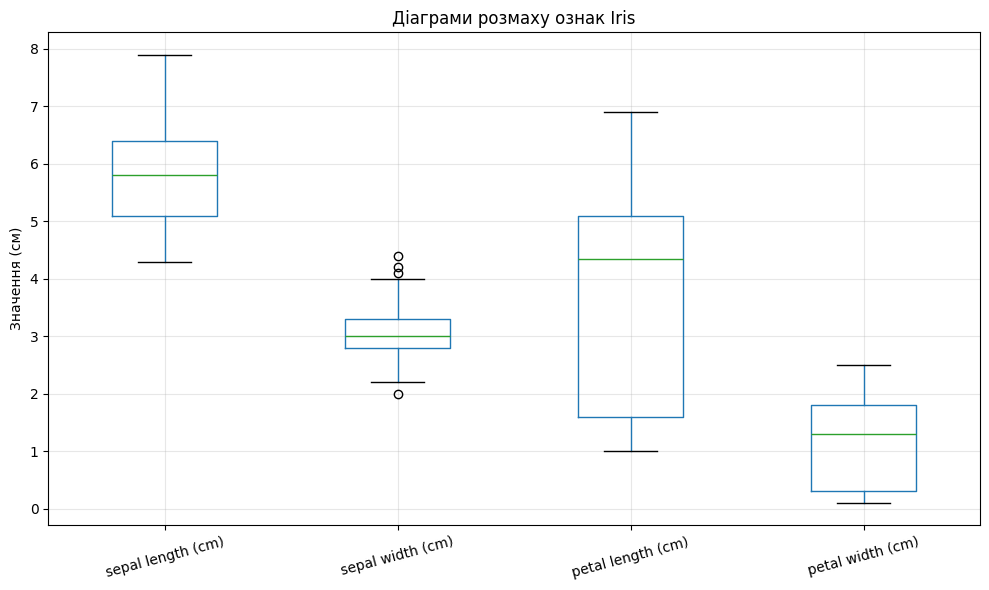

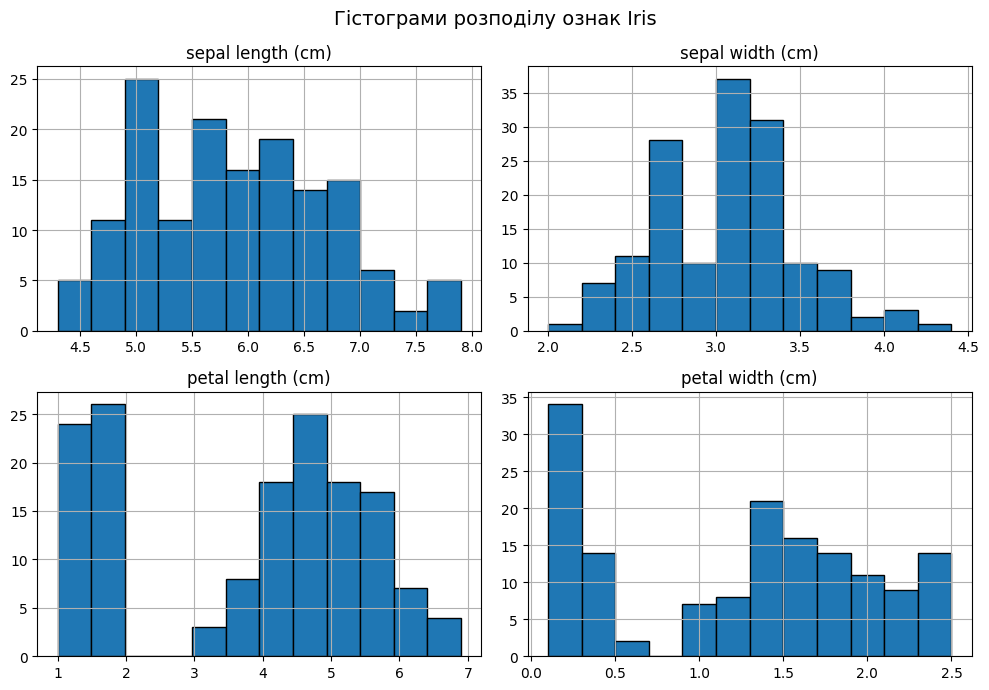

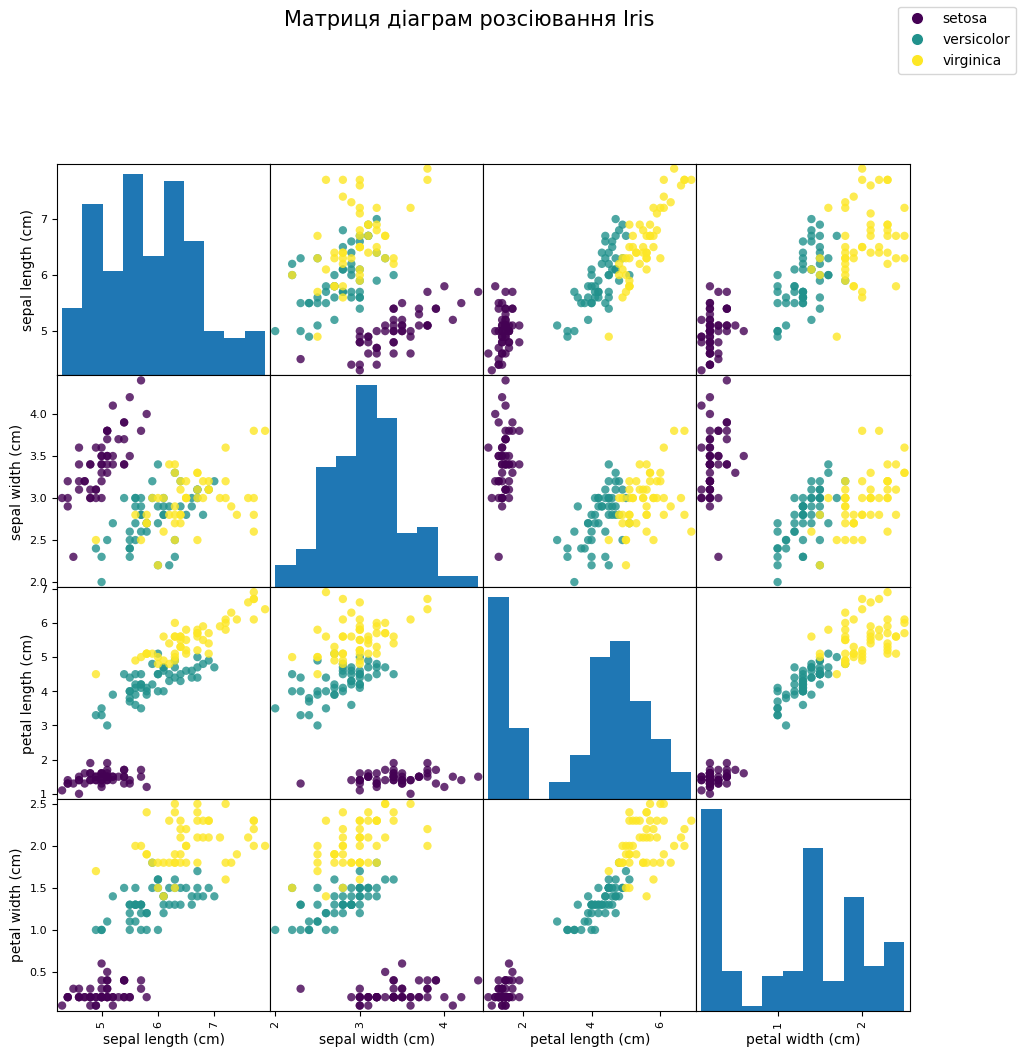


Кількість навчальних прикладів: 120
Кількість тестових прикладів: 30

ПОРІВНЯННЯ АЛГОРИТМІВ:
Algorithm  CV_accuracy_mean  CV_accuracy_std  Test_Accuracy  Precision_macro  Recall_macro  F1_macro  Cohen_Kappa    MCC
      LDA            0.9750           0.0382         1.0000           1.0000        1.0000    1.0000       1.0000 1.0000
      KNN            0.9583           0.0672         0.9667           0.9697        0.9667    0.9666       0.9500 0.9516
      SVM            0.9583           0.0559         0.9667           0.9697        0.9667    0.9666       0.9500 0.9516
       LR            0.9500           0.0553         0.9667           0.9697        0.9667    0.9666       0.9500 0.9516
       NB            0.9500           0.0764         0.9667           0.9697        0.9667    0.9666       0.9500 0.9516
     CART            0.9167           0.0745         0.9667           0.9697        0.9667    0.9666       0.9500 0.9516


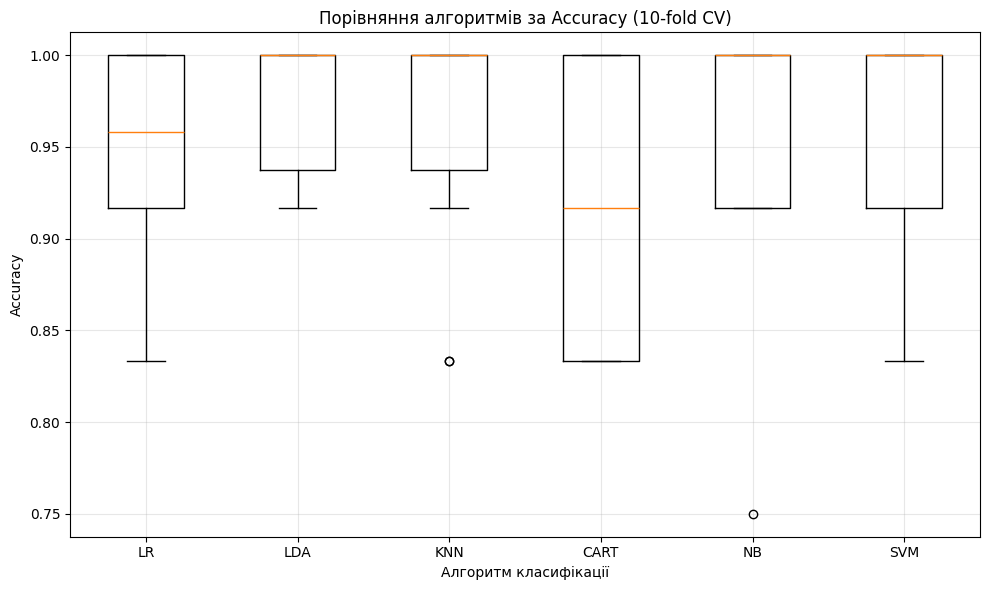

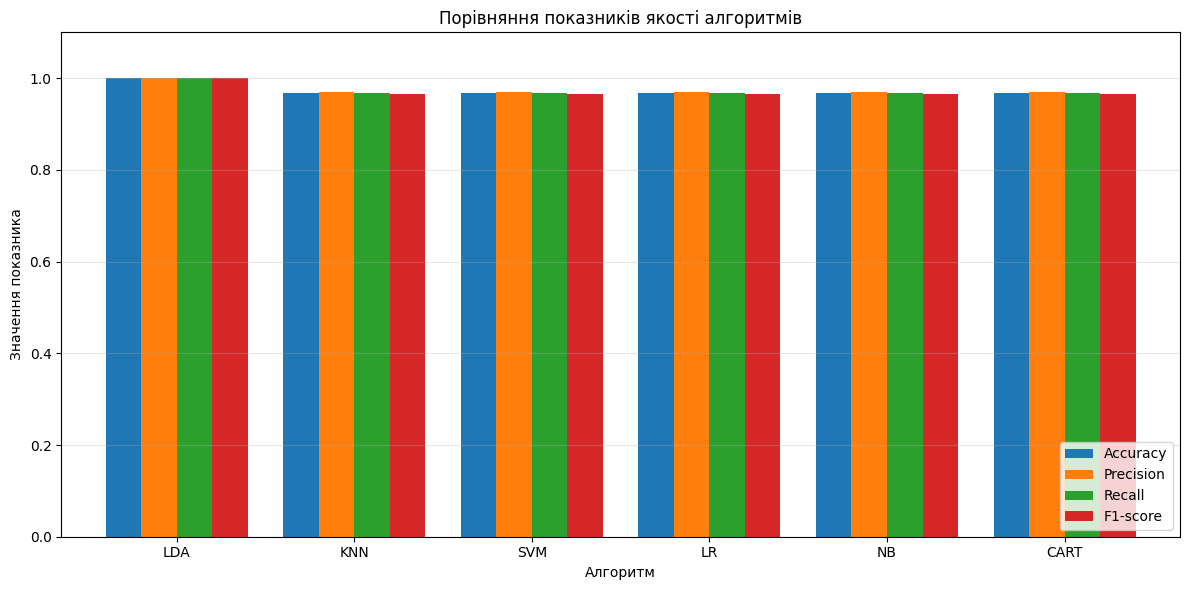


НАЙКРАЩИЙ АЛГОРИТМ: LDA

Матриця помилок:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Звіт класифікації:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



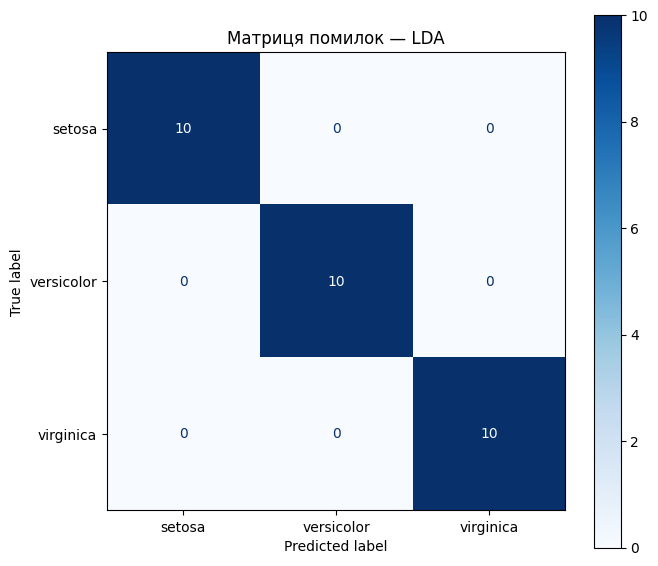


ПРОГНОЗ ДЛЯ НОВОЇ КВІТКИ:
Вхідні характеристики: [[5.  2.9 1.  0.2]]
Форма X_new: (1, 4)
Передбачений код класу: 0
Сорт ірису: setosa

ВИСНОВОК ДО ЗАВДАННЯ 2.3

У ході роботи було проведено класифікацію трьох сортів ірисів:
setosa, versicolor та virginica.

Було досліджено шість алгоритмів:
логістичну регресію, LDA, KNN, дерево рішень,
наївний баєсовський класифікатор та SVM.

Найкращим за середньою точністю 10-кратної
крос-валідації виявився алгоритм LDA.

Показники найкращої моделі:
Accuracy = 1.0000
F1-score = 1.0000
Cohen's Kappa = 1.0000
MCC = 1.0000

Для нової квітки з параметрами [5.0, 2.9, 1.0, 0.2]
модель визначила сорт setosa.

Отже, побудована модель дозволяє класифікувати
іриси за чотирма вимірюваними характеристиками.



In [7]:

# ЗАВДАННЯ 2.3. Класифікація сортів ірисів та прогноз для нової квітки

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import scatter_matrix
from matplotlib.lines import Line2D

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    cohen_kappa_score, matthews_corrcoef,
    ConfusionMatrixDisplay
)

# =========================================================
# 1. ЗАВАНТАЖЕННЯ ТА ОЗНАЙОМЛЕННЯ З ДАНИМИ
# =========================================================

iris = load_iris()
X = iris.data
y = iris.target

print("Назви класів:", iris.target_names)
print("Назви ознак:", iris.feature_names)
print("Розмір набору даних:", X.shape)

dataset = pd.DataFrame(X, columns=iris.feature_names)
dataset["class"] = [iris.target_names[i] for i in y]

print("\nПерші 5 рядків:")
print(dataset.head())

print("\nСтатистичний опис:")
print(dataset.describe())

print("\nКількість квіток кожного класу:")
print(dataset.groupby("class").size())

# =========================================================
# 2. ВІЗУАЛІЗАЦІЯ ДАНИХ
# =========================================================

# Графік 1. Діаграми розмаху (Boxplot)
plt.figure(figsize=(10, 6))
dataset.iloc[:, :4].boxplot()
plt.title("Діаграми розмаху ознак Iris")
plt.ylabel("Значення (см)")
plt.xticks(rotation=15)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Графік 2. Гістограми розподілу ознак
dataset.iloc[:, :4].hist(
    figsize=(10, 7),
    bins=12,
    edgecolor="black"
)
plt.suptitle("Гістограми розподілу ознак Iris", fontsize=14)
plt.tight_layout()
plt.show()

# Графік 3. Матриця діаграм розсіювання
scatter_data = pd.DataFrame(X, columns=iris.feature_names)

axes = scatter_matrix(
    scatter_data,
    figsize=(11, 11),
    diagonal="hist",
    c=y,
    cmap="viridis",
    alpha=0.8,
    marker="o"
)

fig = plt.gcf()
fig.suptitle("Матриця діаграм розсіювання Iris", fontsize=15, y=1.02)

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           label=iris.target_names[i],
           markerfacecolor=plt.cm.viridis(i / 2),
           markersize=9)
    for i in range(3)
]
fig.legend(handles=legend_elements, loc="upper right")
plt.show()

# =========================================================
# 3. РОЗДІЛЕННЯ НА НАВЧАЛЬНУ ТА ТЕСТОВУ ВИБІРКИ
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

print("\nКількість навчальних прикладів:", len(X_train))
print("Кількість тестових прикладів:", len(X_test))

# =========================================================
# 4. СТВОРЕННЯ ШЕСТИ АЛГОРИТМІВ КЛАСИФІКАЦІЇ
# =========================================================

models = {
    "LR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=1))
    ]),

    "LDA": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis())
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "CART": DecisionTreeClassifier(random_state=1),

    "NB": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", gamma="scale", C=1.0))
    ])
}

# =========================================================
# 5. ОЦІНЮВАННЯ АЛГОРИТМІВ ЗА ДОПОМОГОЮ КРОС-ВАЛІДАЦІЇ
# =========================================================

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

results = []
cv_results_dict = {}
trained_models = {}
predictions_dict = {}

for name, model in models.items():

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results_dict[name] = cv_scores

    model.fit(X_train, y_train)
    trained_models[name] = model

    pred = model.predict(X_test)
    predictions_dict[name] = pred

    results.append({
        "Algorithm": name,
        "CV_accuracy_mean": cv_scores.mean(),
        "CV_accuracy_std": cv_scores.std(),
        "Test_Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Cohen_Kappa": cohen_kappa_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["CV_accuracy_mean", "F1_macro"],
    ascending=False
).reset_index(drop=True)

print("\nПОРІВНЯННЯ АЛГОРИТМІВ:")
print(results_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

# =========================================================
# 6. ГРАФІК 4. ПОРІВНЯННЯ АЛГОРИТМІВ ЗА КРОС-ВАЛІДАЦІЄЮ
# =========================================================

plt.figure(figsize=(10, 6))

plt.boxplot(
    [cv_results_dict[name] for name in models.keys()],
    tick_labels=list(models.keys())
)

plt.title("Порівняння алгоритмів за Accuracy (10-fold CV)")
plt.xlabel("Алгоритм класифікації")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 7. ГРАФІК 5. ПОРІВНЯННЯ ПОКАЗНИКІВ ЯКОСТІ
# =========================================================

metrics_to_plot = [
    "Test_Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro"
]

plot_data = results_df.set_index("Algorithm")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Порівняння показників якості алгоритмів")
plt.xlabel("Алгоритм")
plt.ylabel("Значення показника")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(
    ["Accuracy", "Precision", "Recall", "F1-score"],
    loc="lower right"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 8. ВИБІР НАЙКРАЩОГО АЛГОРИТМУ
# =========================================================

best_name = results_df.loc[0, "Algorithm"]
best_model = trained_models[best_name]
best_pred = predictions_dict[best_name]

print("\nНАЙКРАЩИЙ АЛГОРИТМ:", best_name)

print("\nМатриця помилок:")
cm = confusion_matrix(y_test, best_pred)
print(cm)

print("\nЗвіт класифікації:")
print(classification_report(
    y_test,
    best_pred,
    target_names=iris.target_names,
    zero_division=0
))

# =========================================================
# 9. ГРАФІК 6. МАТРИЦЯ ПОМИЛОК НАЙКРАЩОГО АЛГОРИТМУ
# =========================================================

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=iris.target_names,
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title(f"Матриця помилок — {best_name}")
plt.tight_layout()
plt.show()

# =========================================================
# 10. КРОК 8. ПРОГНОЗ ДЛЯ НОВОЇ КВІТКИ
# =========================================================

X_new = np.array([[5.0, 2.9, 1.0, 0.2]])

prediction = best_model.predict(X_new)[0]

print("\nПРОГНОЗ ДЛЯ НОВОЇ КВІТКИ:")
print("Вхідні характеристики:", X_new)
print("Форма X_new:", X_new.shape)
print("Передбачений код класу:", prediction)
print("Сорт ірису:", iris.target_names[prediction])

# =========================================================
# 11. ВИСНОВОК
# =========================================================

best_accuracy = accuracy_score(y_test, best_pred)
best_f1 = f1_score(
    y_test, best_pred, average="macro", zero_division=0
)
best_kappa = cohen_kappa_score(y_test, best_pred)
best_mcc = matthews_corrcoef(y_test, best_pred)

print("\n" + "=" * 60)
print("ВИСНОВОК ДО ЗАВДАННЯ 2.3")
print("=" * 60)

print(f"""
У ході роботи було проведено класифікацію трьох сортів ірисів:
setosa, versicolor та virginica.

Було досліджено шість алгоритмів:
логістичну регресію, LDA, KNN, дерево рішень,
наївний баєсовський класифікатор та SVM.

Найкращим за середньою точністю 10-кратної
крос-валідації виявився алгоритм {best_name}.

Показники найкращої моделі:
Accuracy = {best_accuracy:.4f}
F1-score = {best_f1:.4f}
Cohen's Kappa = {best_kappa:.4f}
MCC = {best_mcc:.4f}

Для нової квітки з параметрами [5.0, 2.9, 1.0, 0.2]
модель визначила сорт {iris.target_names[prediction]}.

Отже, побудована модель дозволяє класифікувати
іриси за чотирма вимірюваними характеристиками.
""")


In [6]:
# ЗАВДАННЯ 2.4. Порівняння шести алгоритмів класифікації income_data.txt
# Щоб усі алгоритми (зокрема KNN та SVM) виконувалися у Colab за прийнятний час,
# використовується збалансована підвибірка до 3000 записів кожного класу.

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             cohen_kappa_score, matthews_corrcoef)

FILE_PATH = "/content/income_data.txt"
MAX_PER_CLASS = 3000  # Можна збільшити, якщо Colab має достатньо ресурсів.

feature_names = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country"
]
columns = feature_names + ["income"]
numeric_features = ["age", "fnlwgt", "education_num", "capital_gain",
                    "capital_loss", "hours_per_week"]
categorical_features = [c for c in feature_names if c not in numeric_features]

df = pd.read_csv(FILE_PATH, header=None, names=columns,
                 skipinitialspace=True, na_values=["?", " ?"], comment="|")
for col in categorical_features + ["income"]:
    df[col] = df[col].astype("string").str.strip()
for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["income"] = df["income"].str.replace(r"\.$", "", regex=True).str.strip()
df = df.dropna(subset=feature_names + ["income"])
df = df[df["income"].isin(["<=50K", ">50K"])].copy()

parts = [g.sample(n=min(len(g), MAX_PER_CLASS), random_state=42)
         for _, g in df.groupby("income")]
df = pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)
X, y = df[feature_names], df["income"]
print("Розмір збалансованої підвибірки:", X.shape)
print("Кількість записів за класами:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=5, stratify=y
)

# Для LDA та GaussianNB потрібен щільний масив; тому OneHotEncoder повертає dense-матрицю.
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ], sparse_threshold=0)

models = {
    "LR": LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced"),
    "LDA": LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "CART": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "NB": GaussianNB(),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")
}

results = []
trained_models = {}
for name, estimator in models.items():
    model = Pipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", estimator)
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    trained_models[name] = model
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "Cohen_Kappa": cohen_kappa_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values(
    by=["F1_macro", "MCC"], ascending=False
).reset_index(drop=True)
print("\nПОРІВНЯННЯ АЛГОРИТМІВ ДЛЯ INCOME DATA:")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

best_name = results_df.loc[0, "Algorithm"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test)
print(f"\nНайкращий алгоритм за F1 macro та MCC: {best_name}")
print("Матриця помилок:")
print(confusion_matrix(y_test, best_pred))
print("Звіт класифікації:\n", classification_report(y_test, best_pred, zero_division=0))

print("\nВИСНОВОК ДО ЗАВДАННЯ 2.4:")
print(f"Найкращим на цій тестовій вибірці за F1 macro та MCC є алгоритм {best_name}. "
      f"Його Accuracy = {accuracy_score(y_test, best_pred):.4f}, "
      f"F1 macro = {f1_score(y_test, best_pred, average='macro', zero_division=0):.4f}, "
      f"Cohen's Kappa = {cohen_kappa_score(y_test, best_pred):.4f}, "
      f"MCC = {matthews_corrcoef(y_test, best_pred):.4f}. "
      "Cohen's Kappa враховує збіги, які могли б виникнути випадково, а MCC враховує TP, TN, FP і FN. "
      "Більші значення цих коефіцієнтів, ближчі до 1, свідчать про кращу класифікацію.")


Розмір збалансованої підвибірки: (6000, 14)
Кількість записів за класами:
 income
<=50K    3000
>50K     3000
Name: count, dtype: Int64

ПОРІВНЯННЯ АЛГОРИТМІВ ДЛЯ INCOME DATA:
Algorithm  Accuracy  Precision_macro  Recall_macro  F1_macro  F1_weighted  Cohen_Kappa    MCC
      SVM    0.8350           0.8396        0.8350    0.8344       0.8344       0.6700 0.6746
       LR    0.8333           0.8347        0.8333    0.8332       0.8332       0.6667 0.6680
      KNN    0.8025           0.8055        0.8025    0.8020       0.8020       0.6050 0.6079
      LDA    0.8008           0.8073        0.8008    0.7998       0.7998       0.6017 0.6081
     CART    0.7675           0.7676        0.7675    0.7675       0.7675       0.5350 0.5351
       NB    0.7150           0.7647        0.7150    0.7010       0.7010       0.4300 0.4771

Найкращий алгоритм за F1 macro та MCC: SVM
Матриця помилок:
[[466 134]
 [ 64 536]]
Звіт класифікації:
               precision    recall  f1-score   support

       

Назви класів: ['setosa' 'versicolor' 'virginica']
Назви ознак: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Розмір набору даних: (150, 4)

Кількість навчальних прикладів: 105
Кількість тестових прикладів: 45

Передбачені класи:
[2 1 0 2 0 2 0 2 1 1 1 2 1 2 2 0 2 1 0 0 2 2 0 0 2 0 0 1 1 0 2 2 0 2 2 2 0
 2 2 1 2 0 2 0 0]

Справжні класи:
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 1 1 1 2 0 2 0 0]

ПОКАЗНИКИ ЯКОСТІ КЛАСИФІКАЦІЇ RIDGE
Accuracy: 0.7556
Precision: 0.8333
Recall: 0.7556
F1 Score: 0.7503
Cohen Kappa Score: 0.6431
Matthews Corrcoef: 0.6831

ЗВІТ ПРО КЛАСИФІКАЦІЮ:
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        16
  versicolor     0.8889    0.4444    0.5926        18
   virginica     0.5000    0.9091    0.6452        11

    accuracy                         0.7556        45
   macro avg     0.7963    0.7845    0.7459        45
weighted avg     0.8333  

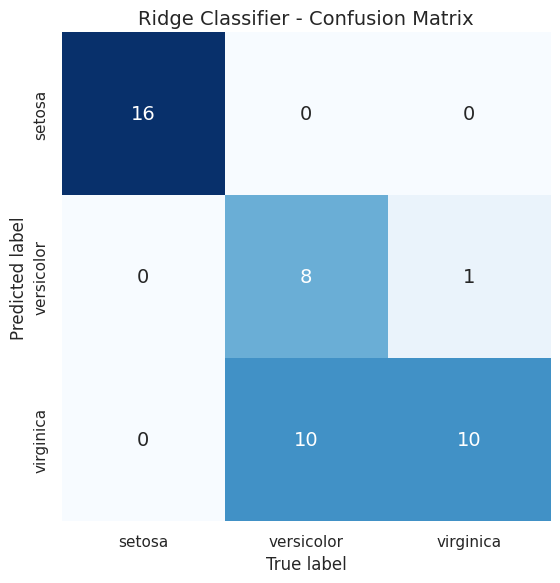

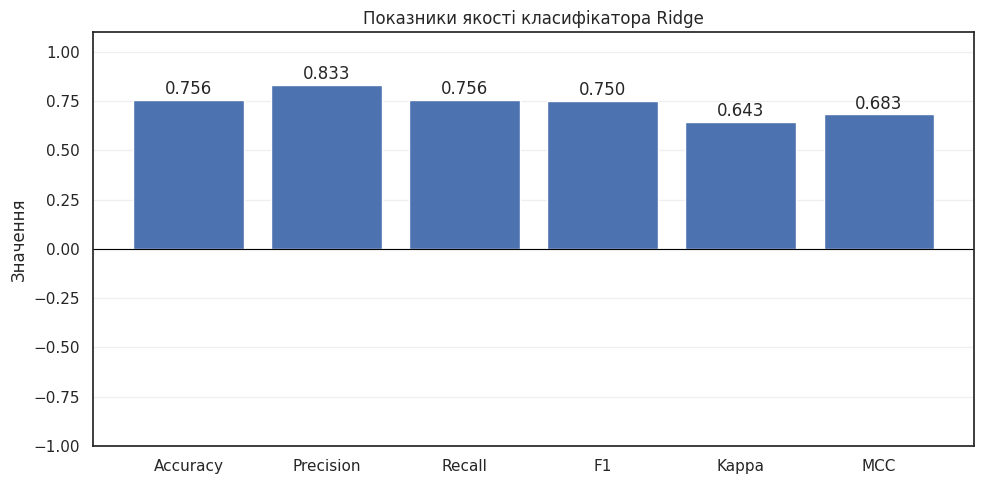


ВИСНОВОК ДО ЗАВДАННЯ 2.5

У ході роботи було виконано класифікацію набору даних Iris
за допомогою лінійного класифікатора RidgeClassifier.

Для навчання використано 70% набору даних,
для тестування — 30%.

Параметри класифікатора:
tol = 0.01;
solver = sag;
alpha = 1.0 (значення за замовчуванням).

Отримані показники якості:

Accuracy = 0.7556
Precision = 0.8333
Recall = 0.7556
F1-score = 0.7503
Cohen Kappa = 0.6431
Matthews Corrcoef = 0.6831

Матриця помилок дозволяє побачити кількість
правильно та неправильно класифікованих квіток.

Коефіцієнт Коена Каппа оцінює узгодженість
між передбаченими та справжніми класами
з урахуванням випадкових збігів.

Коефіцієнт Метьюза оцінює якість класифікації,
враховуючи правильні та помилкові передбачення.

Отже, RidgeClassifier дозволяє класифікувати
сорти ірисів за їхніми характеристиками.

Графіки збережено у файлах Confusion.jpg та Confusion.svg


In [8]:

# ============================================================
# ЗАВДАННЯ 2.5. Класифікація даних лінійним класифікатором Ridge
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from io import BytesIO

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix

# ============================================================
# 1. ЗАВАНТАЖЕННЯ ДАНИХ
# ============================================================

iris = load_iris()

X = iris.data
y = iris.target

print("Назви класів:", iris.target_names)
print("Назви ознак:", iris.feature_names)
print("Розмір набору даних:", X.shape)

# ============================================================
# 2. РОЗДІЛЕННЯ НА НАВЧАЛЬНУ ТА ТЕСТОВУ ВИБІРКИ
# ============================================================

Xtrain, Xtest, ytrain, ytest = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0
)

print("\nКількість навчальних прикладів:", len(Xtrain))
print("Кількість тестових прикладів:", len(Xtest))

# ============================================================
# 3. СТВОРЕННЯ ТА НАВЧАННЯ RIDGE CLASSIFIER
# ============================================================

clf = RidgeClassifier(
    tol=1e-2,
    solver="sag"
)

clf.fit(Xtrain, ytrain)

# ============================================================
# 4. ПРОГНОЗУВАННЯ
# ============================================================

ypred = clf.predict(Xtest)

print("\nПередбачені класи:")
print(ypred)

print("\nСправжні класи:")
print(ytest)

# ============================================================
# 5. РОЗРАХУНОК ПОКАЗНИКІВ ЯКОСТІ
# ============================================================

accuracy = metrics.accuracy_score(ytest, ypred)

precision = metrics.precision_score(
    ytest, ypred, average="weighted"
)

recall = metrics.recall_score(
    ytest, ypred, average="weighted"
)

f1 = metrics.f1_score(
    ytest, ypred, average="weighted"
)

kappa = metrics.cohen_kappa_score(ytest, ypred)

mcc = metrics.matthews_corrcoef(ytest, ypred)

print("\n" + "=" * 50)
print("ПОКАЗНИКИ ЯКОСТІ КЛАСИФІКАЦІЇ RIDGE")
print("=" * 50)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("Cohen Kappa Score:", round(kappa, 4))
print("Matthews Corrcoef:", round(mcc, 4))

# ============================================================
# 6. ЗВІТ ПРО КЛАСИФІКАЦІЮ
# ============================================================

print("\nЗВІТ ПРО КЛАСИФІКАЦІЮ:")
print(
    metrics.classification_report(
        ytest,
        ypred,
        target_names=iris.target_names,
        digits=4
    )
)

# ============================================================
# 7. МАТРИЦЯ ПОМИЛОК
# ============================================================

mat = confusion_matrix(ytest, ypred)

print("МАТРИЦЯ ПОМИЛОК:")
print(mat)

# ============================================================
# 8. ВІЗУАЛІЗАЦІЯ МАТРИЦІ ПОМИЛОК З SEABORN
# ============================================================

sns.set_theme(style="white")

plt.figure(figsize=(8, 6))

sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    annot_kws={"size": 14}
)

plt.xlabel("True label", fontsize=12)
plt.ylabel("Predicted label", fontsize=12)
plt.title("Ridge Classifier - Confusion Matrix", fontsize=14)

plt.tight_layout()

# Збереження графіка
plt.savefig("Confusion.jpg", dpi=300, bbox_inches="tight")
plt.savefig("Confusion.svg", format="svg", bbox_inches="tight")

plt.show()

# ============================================================
# 9. ДОДАТКОВО: ГРАФІК ПОКАЗНИКІВ ЯКОСТІ
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Kappa",
    "MCC"
]

metric_values = [
    accuracy,
    precision,
    recall,
    f1,
    kappa,
    mcc
]

plt.figure(figsize=(10, 5))

bars = plt.bar(metric_names, metric_values)

plt.title("Показники якості класифікатора Ridge")
plt.ylabel("Значення")
plt.ylim(-1, 1.1)
plt.axhline(0, color="black", linewidth=0.8)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + (0.03 if value >= 0 else -0.07),
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 10. ВИСНОВОК
# ============================================================

print("\n" + "=" * 60)
print("ВИСНОВОК ДО ЗАВДАННЯ 2.5")
print("=" * 60)

print(f"""
У ході роботи було виконано класифікацію набору даних Iris
за допомогою лінійного класифікатора RidgeClassifier.

Для навчання використано 70% набору даних,
для тестування — 30%.

Параметри класифікатора:
tol = 0.01;
solver = sag;
alpha = 1.0 (значення за замовчуванням).

Отримані показники якості:

Accuracy = {accuracy:.4f}
Precision = {precision:.4f}
Recall = {recall:.4f}
F1-score = {f1:.4f}
Cohen Kappa = {kappa:.4f}
Matthews Corrcoef = {mcc:.4f}

Матриця помилок дозволяє побачити кількість
правильно та неправильно класифікованих квіток.

Коефіцієнт Коена Каппа оцінює узгодженість
між передбаченими та справжніми класами
з урахуванням випадкових збігів.

Коефіцієнт Метьюза оцінює якість класифікації,
враховуючи правильні та помилкові передбачення.

Отже, RidgeClassifier дозволяє класифікувати
сорти ірисів за їхніми характеристиками.
""")

print("Графіки збережено у файлах Confusion.jpg та Confusion.svg")
